In [ ]:
# Bibliotecas
library(ggplot2)

In [ ]:
# Defina o diretório de trabalho (opcional - pode não ser necessário no Colab)
# setwd('C:/Dados')

# Defina os nomes das colunas
names <- c("horario", "temp", "vento", "umid", "sensa")

# Crie uma conexão com o arquivo CSV online
con <- url("https://ic.unicamp.br/~zanoni/cepagri/cepagri.csv")

# Leia a tabela de dados do arquivo CSV
cepagri <- read.table(con, header = FALSE, fill = TRUE, sep = ";", col.names = names)

In [ ]:
# Visualize as primeiras linhas do dataframe
head(cepagri)

,horario,temp,vento,umid,sensa
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,02/03/2014-19:08,23.7,59.3,77.1,22.6
2,02/03/2014-19:18,23.4,59.1,77.9,22.3
3,02/03/2014-19:28,23.2,56.7,78.9,22.1
4,02/03/2014-19:38,23.0,55.4,79.2,21.9
5,02/03/2014-19:48,22.8,52.6,79.7,21.7
6,02/03/2014-19:58,22.6,62.6,80.7,21.5


In [ ]:
# Visualize as últimas linhas do dataframe
tail(cepagri)

,horario,temp,vento,umid,sensa
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
571414,03/04/2025-20:20,20.9,8.1,95.4,NA
571415,03/04/2025-20:30,20.8,2.2,95.6,NA
571416,03/04/2025-20:40,20.8,6.5,95.8,NA
571417,03/04/2025-20:50,20.9,8.6,95.7,NA
571418,03/04/2025-21:00,20.9,9.9,95.6,NA
571419,03/04/2025-21:10,20.9,7.0,95.5,NA


In [ ]:
class (cepagri)

[1] "data.frame"

In [ ]:
typeof(cepagri)

[1] "list"

In [ ]:
sapply(cepagri,class)

horario        temp       vento        umid       sensa 
"character" "character"   "numeric"   "numeric"   "numeric"

In [ ]:
# Temp
cepagri$temp <- as.numeric(cepagri$temp)
class(cepagri$temp)

[1] "numeric"

In [ ]:
# Horário
cepagri$horario <- as.POSIXct(cepagri$horario, format = '%d/%m/%Y-%H:%M', tz = "America/Sao_Paulo")
class(cepagri$horario)

[1] "POSIXct" "POSIXt"

In [ ]:
totalcepagri <- nrow(cepagri) # Total de linhas =
print(totalcepagri)

[1] 571419


In [ ]:
# Filtrando o período de 01/01/2025 a 26/03/2025
cepagri <- cepagri[cepagri$horario >= as.POSIXct("2025-01-01", tz = "America/Sao_Paulo") & cepagri$horario < as.POSIXct("2025-03-27", tz = "America/Sao_Paulo"), ]
nrow(cepagri)

[1] 11987

In [ ]:
periodoleitura <- nrow(cepagri)
totalexcluidas <- (totalcepagri-periodoleitura)
print(totalexcluidas)

[1] 559432


In [ ]:
head(cepagri)

,horario,temp,vento,umid,sensa
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
558302,2025-01-01 00:00:00,21.1,0,0,NA
558303,2025-01-01 00:10:00,21.0,0,0,NA
558304,2025-01-01 00:20:00,21.2,0,0,NA
558305,2025-01-01 00:30:00,20.9,0,0,NA
558306,2025-01-01 00:40:00,20.6,0,0,NA
558307,2025-01-01 00:50:00,20.5,0,0,NA


In [ ]:
tail(cepagri)

,horario,temp,vento,umid,sensa
,<dttm>,<dbl>,<dbl>,<dbl>,<dbl>
570283,2025-03-26 23:00:00,21.7,10.3,88.6,NA
570284,2025-03-26 23:10:00,21.7,10.6,88.8,NA
570285,2025-03-26 23:20:00,21.7,9.4,89.2,NA
570286,2025-03-26 23:30:00,21.4,6.8,89.8,NA
570287,2025-03-26 23:40:00,21.3,7.6,90.5,NA
570288,2025-03-26 23:50:00,21.3,11.3,90.7,NA


In [ ]:
# Criar duas colunas: ano e mês
cepagri$horario <- as.POSIXlt(cepagri$horario)

cepagri$ano <- unclass(cepagri$horario)$year + 1900
cepagri$mes <- unclass(cepagri$horario)$mon + 1

`geom_smooth()` using method = 'gam' and formula = 'y ~ s(x, bs = "cs")'
Warning message:
“Removed 900 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 900 rows containing missing values or values outside the scale range
(`geom_point()`).”


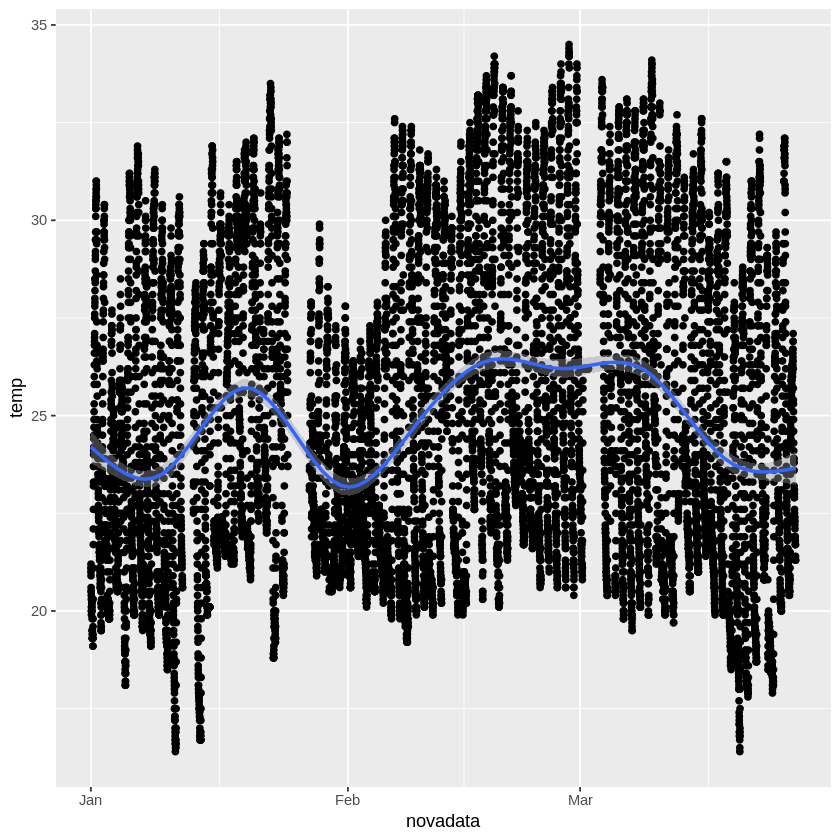

In [ ]:
# verificando os dados de temperatura através de um grafico
novadata <- as.POSIXct(cepagri$horario)

gtm18 <- ggplot(cepagri, aes(x = novadata, y = temp))
gtm18 <- gtm18 + geom_point()
gtm18 <- gtm18 + geom_smooth()
gtm18

In [ ]:
summary(cepagri)

med <- mean(cepagri$temp, na.rm = TRUE) # média de temperatura
md <- median(cepagri$temp, na.rm = TRUE) # mediana
dp <- sd(cepagri$temp, na.rm = TRUE) # desvio padrao
variancia <- var(cepagri$temp, na.rm = TRUE) # variancia

mt <- max(cepagri$temp, na.rm = TRUE) # valor máximo
mint <- min(cepagri$temp, na.rm = TRUE) # valor mínimo
quartis <- quantile(cepagri$temp, na.rm = TRUE) # gerando os quartis

# Exibindo os resultados (opcional)
print(paste("Média da temperatura:", med))
print(paste("Mediana da temperatura:", md))
print(paste("Desvio padrão da temperatura:", dp))
print(paste("Variância da temperatura:", variancia))
print(paste("Temperatura máxima:", mt))
print(paste("Temperatura mínima:", mint))
print("Quartis da temperatura:")
print(quartis)

    horario                            temp           vento       
 Min.   :2025-01-01 00:00:00.00   Min.   :16.40   Min.   : 0.000  
 1st Qu.:2025-01-23 10:45:00.00   1st Qu.:21.50   1st Qu.: 0.000  
 Median :2025-02-13 09:00:00.00   Median :24.00   Median : 4.900  
 Mean   :2025-02-13 02:13:04.07   Mean   :24.85   Mean   : 6.079  
 3rd Qu.:2025-03-06 04:25:00.00   3rd Qu.:28.10   3rd Qu.: 9.700  
 Max.   :2025-03-26 23:50:00.00   Max.   :34.50   Max.   :36.700  
                                  NA's   :900     NA's   :900     
      umid            sensa            ano            mes       
 Min.   :  0.00   Min.   : NA     Min.   :2025   Min.   :1.000  
 1st Qu.:  0.00   1st Qu.: NA     1st Qu.:2025   1st Qu.:1.000  
 Median : 66.60   Median : NA     Median :2025   Median :2.000  
 Mean   : 53.82   Mean   :NaN     Mean   :2025   Mean   :1.961  
 3rd Qu.: 85.20   3rd Qu.: NA     3rd Qu.:2025   3rd Qu.:3.000  
 Max.   :100.00   Max.   : NA     Max.   :2025   Max.   :3.000  
 NA's   :

[1] "Média da temperatura: 24.8542346892757"
[1] "Mediana da temperatura: 24"
[1] "Desvio padrão da temperatura: 3.99282866396649"
[1] "Variância da temperatura: 15.9426807397924"
[1] "Temperatura máxima: 34.5"
[1] "Temperatura mínima: 16.4"
[1] "Quartis da temperatura:"
  0%  25%  50%  75% 100% 
16.4 21.5 24.0 28.1 34.5 


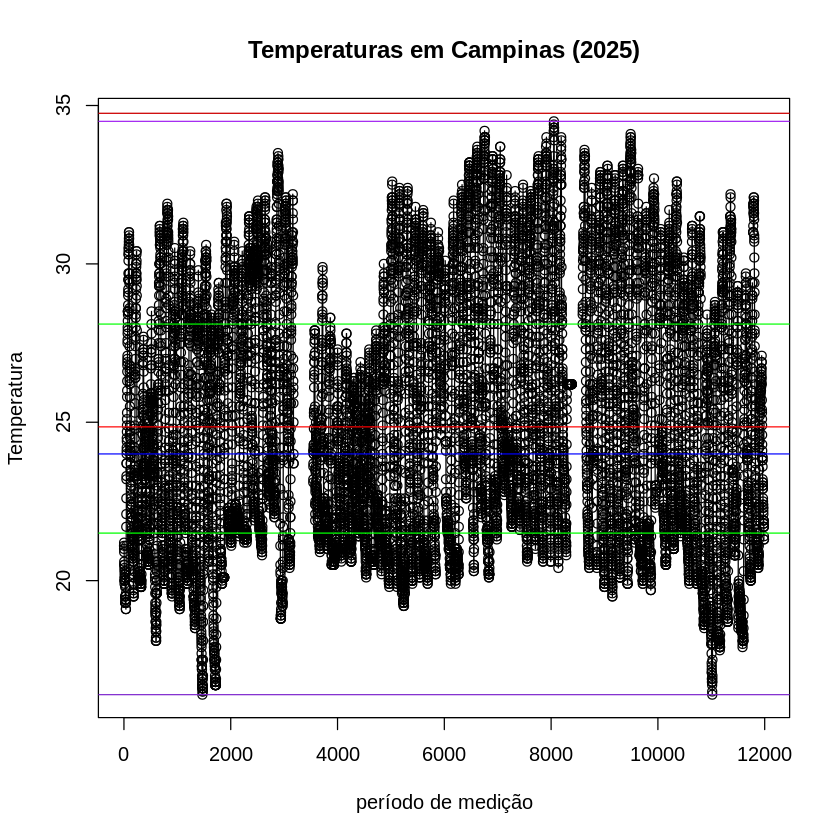

In [ ]:
plot(cepagri$temp, xlab = "período de medição", ylab = "Temperatura", main = "Temperaturas em Campinas (2025)")
lines(cepagri$temp) # plotando os dados em linha

abline(h = med, col = "red") # indicador da média
abline(h = md, col = "blue") # indicador da mediana

abline(h = mt, col = "purple") # indicador do máximo
abline(h = mint, col = "purple3") # indicador do minimo

quartis <- quantile(cepagri$temp, na.rm = TRUE) # armazenando os quartis
abline(h = quartis[[2]], col = "green1") # plotando o 1º quartil (25%)

abline(h = quartis[[4]], col = "green1") # plotando o 3º quartil (75%)
amplitude <- quartis[[4]] - quartis[[2]] # calculando a amplitude interquartil (IQR)

limsup <- mean(cepagri$temp, na.rm = TRUE) + 1.5 * amplitude # cálculo do limite superior para outliers (método IQR)
liminf <- mean(cepagri$temp, na.rm = TRUE) - 1.5 * amplitude # cálculo do limite inferior para outliers (método IQR)

abline(h = limsup, col = "red3") # plotando o limite superior
abline(h = liminf, col = "red3") # plotando o limite inferior